# No-Churn Telecom: Customer Churn Prediction (PM-PR-0017)

## Business Case
No-Churn Telecom is an established telecom operator in Europe. Competition has made customer retention difficult, and the churn rate (the share of customers migrating to competitors) is well above 10%.

## Project Goals
1. **Understand the variables that influence customers to migrate**
2. **Create churn risk scores** that can drive retention campaigns
3. **Create a new variable `CHURN-FLAG`** with values YES (1) or NO (0), so email campaigns with offers can target the customers flagged YES

The results should also help the company give extra attention to likely churners at customer touch points: customer-care support, request fulfilment and automatic high-priority ticket handling.

## Data
SQL database `project_telecom`, table `telecom_churn_data`.

---
# 1. Setup and Data Loading

In [1]:
# Run once if a library is missing (remove the # to use), then restart the kernel
# !pip install pymysql sqlalchemy lightgbm xgboost

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")
sns.set_style("whitegrid")

from sklearn.model_selection import (train_test_split,StratifiedKFold,cross_val_score,GridSearchCV,RandomizedSearchCV)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (roc_auc_score, precision_score, recall_score, f1_score,classification_report, confusion_matrix, 
ConfusionMatrixDisplay, roc_curve, precision_recall_curve)
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier

print("Libraries loaded")

Libraries loaded


The data is stored in a MySQL database, so I connect to it with SQLAlchemy and read the table into a pandas DataFrame. The password is typed in when asked (it is not saved in the notebook), and a local CSV backup is saved.

In [3]:
import getpass
from urllib.parse import quote_plus
from sqlalchemy import create_engine

host = "18.136.157.135"
user = "dm_team3"
database = "project_telecom"
password = quote_plus(getpass.getpass("Enter the database password: "))   # copy it from the project document

engine = create_engine(f"mysql+pymysql://{user}:{password}@{host}:3306/{database}")

df = pd.read_sql("SELECT * FROM telecom_churn_data", engine)
df.to_csv("telecom_churn_data.csv", index=False)      # local backup
print("Shape:", df.shape)
df.head()

Enter the database password:  ········


Shape: (243553, 14)


,customer_id,telecom_partner,gender,age,state,city,pincode,date_of_registration,num_dependents,estimated_salary,calls_made,sms_sent,data_used,churn
0,1,Reliance Jio,F,25,Karnataka,Kolkata,755597,2020-01-01,4,124962,44,45,-361,0
1,2,Reliance Jio,F,55,Mizoram,Mumbai,125926,2020-01-01,2,130556,62,39,5973,0
2,3,Vodafone,F,57,Arunachal Pradesh,Delhi,423976,2020-01-01,0,148828,49,24,193,1
3,4,BSNL,M,46,Tamil Nadu,Kolkata,522841,2020-01-01,1,38722,80,25,9377,1
4,5,BSNL,F,26,Tripura,Delhi,740247,2020-01-01,2,55098,78,15,1393,0


---
#  Data Understanding and Quality Checks

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 243553 entries, 0 to 243552
Data columns (total 14 columns):
 #   Column                Non-Null Count   Dtype 
---  ------                --------------   ----- 
 0   customer_id           243553 non-null  int64 
 1   telecom_partner       243553 non-null  object
 2   gender                243553 non-null  object
 3   age                   243553 non-null  int64 
 4   state                 243553 non-null  object
 5   city                  243553 non-null  object
 6   pincode               243553 non-null  int64 
 7   date_of_registration  243553 non-null  object
 8   num_dependents        243553 non-null  int64 
 9   estimated_salary      243553 non-null  int64 
 10  calls_made            243553 non-null  int64 
 11  sms_sent              243553 non-null  int64 
 12  data_used             243553 non-null  int64 
 13  churn                 243553 non-null  int64 
dtypes: int64(9), object(5)
memory usage: 26.0+ MB


In [5]:
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print()
print(df["churn"].value_counts())
print()
print((df["churn"].value_counts(normalize=True) * 100).round(2))

Missing values: 0
Duplicate rows: 0

churn
0    194726
1     48827
Name: count, dtype: int64

churn
0    79.95
1    20.05
Name: proportion, dtype: float64


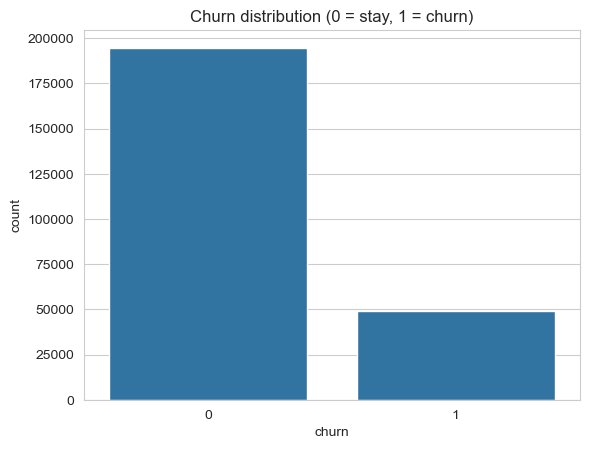

In [6]:
sns.countplot(x="churn", data=df)
plt.title("Churn distribution (0 = stay, 1 = churn)")
plt.show()

**Observation:**
- The data has 243,553 customers and 14 columns, with no missing values and no duplicate rows.
- The target `churn` is already 0/1. About **20%** of customers churn (48,827 churned and 194,726 stayed), so the data is **imbalanced**.

**Inference:** accuracy would be misleading (a model that predicts "stay" for everyone gets about 80% accuracy and finds no churners), so I judge models with **ROC-AUC, precision, recall and F1**.

In [7]:
# Possible data problems
print("Negative calls_made:", (df["calls_made"] < 0).sum())
print("Negative sms_sent  :", (df["sms_sent"] < 0).sum())
print("Negative data_used :", (df["data_used"] < 0).sum())

print("\nUnique pincodes:", df["pincode"].nunique())

df["date_of_registration"] = pd.to_datetime(df["date_of_registration"])
print("\nFirst registration date:", df["date_of_registration"].min())
print("Last registration date :", df["date_of_registration"].max())

Negative calls_made: 6713
Negative sms_sent  : 7375
Negative data_used : 6050

Unique pincodes: 213442

First registration date: 2020-01-01 00:00:00
Last registration date : 2023-05-04 00:00:00


In [8]:
df.describe().T.round(2)

,count,mean,min,25%,50%,75%,max,std
customer_id,243553.0,121777.0,1.0,60889.0,121777.0,182665.0,243553.0,70307.839393
age,243553.0,46.077609,18.0,32.0,46.0,60.0,74.0,16.444029
pincode,243553.0,549501.270541,100006.0,324586.0,548112.0,774994.0,999987.0,259808.860574
date_of_registration,243553,2021-09-01 00:00:00.354748416,2020-01-01 00:00:00,2020-10-31 00:00:00,2021-09-01 00:00:00,2022-07-03 00:00:00,2023-05-04 00:00:00,NaN
num_dependents,243553.0,1.9975,0.0,1.0,2.0,3.0,4.0,1.414941
estimated_salary,243553.0,85021.137839,20000.0,52585.0,84990.0,117488.0,149999.0,37508.963233
calls_made,243553.0,49.010548,-10.0,24.0,49.0,74.0,108.0,29.453556
sms_sent,243553.0,23.945404,-5.0,11.0,24.0,36.0,53.0,14.733575
data_used,243553.0,4993.186025,-987.0,2490.0,4987.0,7493.0,10991.0,2942.019547
churn,243553.0,0.200478,0.0,0.0,0.0,0.0,1.0,0.400359


**Observation:**
- `calls_made` (6,713 rows), `sms_sent` (7,375 rows) and `data_used` (6,050 rows) contain **negative values**, which are impossible. This is about 2.5% to 3% of rows for each column.
- `pincode` has 213,442 unique values for 243,553 customers, so it is almost an identifier. `customer_id` is also an identifier.
- Registration dates run from 2020-01-01 to 2023-05-04.

**Decision:** replace the negative values with 0, drop `customer_id` and `pincode`, and convert the registration date into `tenure_days` (how long the customer has been registered).

---
# Data Cleaning

In [9]:
df_clean = df.copy()      # keep the original data safe

# 1. Replace negative values with 0
for col in ["calls_made", "sms_sent", "data_used"]:
    df_clean[col] = df_clean[col].clip(lower=0)

# 2. Drop columns that are only identifiers
df_clean = df_clean.drop(["customer_id", "pincode"], axis=1)

# 3. Turn the registration date into "days registered"
last_date = df_clean["date_of_registration"].max()
df_clean["tenure_days"] = (last_date - df_clean["date_of_registration"]).dt.days
df_clean = df_clean.drop("date_of_registration", axis=1)

print(df_clean[["calls_made", "sms_sent", "data_used"]].min())
print("Shape:", df_clean.shape)
df_clean.head()

calls_made    0
sms_sent      0
data_used     0
dtype: int64
Shape: (243553, 12)


,telecom_partner,gender,age,state,city,num_dependents,estimated_salary,calls_made,sms_sent,data_used,churn,tenure_days
0,Reliance Jio,F,25,Karnataka,Kolkata,4,124962,44,45,0,0,1219
1,Reliance Jio,F,55,Mizoram,Mumbai,2,130556,62,39,5973,0,1219
2,Vodafone,F,57,Arunachal Pradesh,Delhi,0,148828,49,24,193,1,1219
3,BSNL,M,46,Tamil Nadu,Kolkata,1,38722,80,25,9377,1,1219
4,BSNL,F,26,Tripura,Delhi,2,55098,78,15,1393,0,1219


**Result:** negative values are now 0, the identifier columns are removed and `tenure_days` replaces the date. The cleaned data has 12 columns. (If this cell is run twice it gives a "not found" error, so run the cells from the top to start again.)

---
# Analysis: Which Customers Churn More?
`churn` is 0 or 1, so the average of `churn` for a group multiplied by 100 is that group's **churn rate in %**.

In [10]:
for col in ["telecom_partner", "gender", "city"]:
    print(col)
    print((df_clean.groupby(col)["churn"].mean() * 100).round(2))
    print()

state_churn = (df_clean.groupby("state")["churn"].mean() * 100).sort_values(ascending=False)
print("Highest churn states:\n", state_churn.head(5).round(2))
print("\nLowest churn states:\n", state_churn.tail(5).round(2))

telecom_partner
telecom_partner
Airtel          20.37
BSNL            19.86
Reliance Jio    20.02
Vodafone        19.95
Name: churn, dtype: float64

gender
gender
F    20.30
M    19.88
Name: churn, dtype: float64

city
city
Bangalore    20.05
Chennai      19.76
Delhi        19.75
Hyderabad    20.42
Kolkata      20.16
Mumbai       20.16
Name: churn, dtype: float64

Highest churn states:
 state
Jharkhand           21.12
Karnataka           20.71
Mizoram             20.65
Uttarakhand         20.42
Himachal Pradesh    20.41
Name: churn, dtype: float64

Lowest churn states:
 state
Kerala          19.53
Tripura         19.48
Chhattisgarh    19.43
Punjab          19.43
West Bengal     19.40
Name: churn, dtype: float64


In [11]:
# Average values of customers who stay (0) versus customers who churn (1)
df_clean.groupby("churn")[["age", "num_dependents", "estimated_salary", "calls_made", "sms_sent", "data_used", "tenure_days"]].mean().round(2)

,age,num_dependents,estimated_salary,calls_made,sms_sent,data_used,tenure_days
churn,,,,,,,
0,46.07,2.00,85083.73,49.09,24.04,5000.24,610.29
1,46.11,1.99,84771.53,49.22,23.93,5005.82,608.84


In [12]:
# Churn rate by age group and by data-usage group
age_group = pd.cut(df_clean["age"], bins=[17, 30, 45, 60, 80])
data_group = pd.qcut(df_clean["data_used"], 4, labels=["Low", "Medium", "High", "Very high"])

print((df_clean.groupby(age_group)["churn"].mean() * 100).round(2))
print()
print((df_clean.groupby(data_group)["churn"].mean() * 100).round(2))

age
(17, 30]    19.81
(30, 45]    20.29
(45, 60]    19.93
(60, 80]    20.14
Name: churn, dtype: float64

data_used
Low          19.79
Medium       20.26
High         20.25
Very high    19.89
Name: churn, dtype: float64


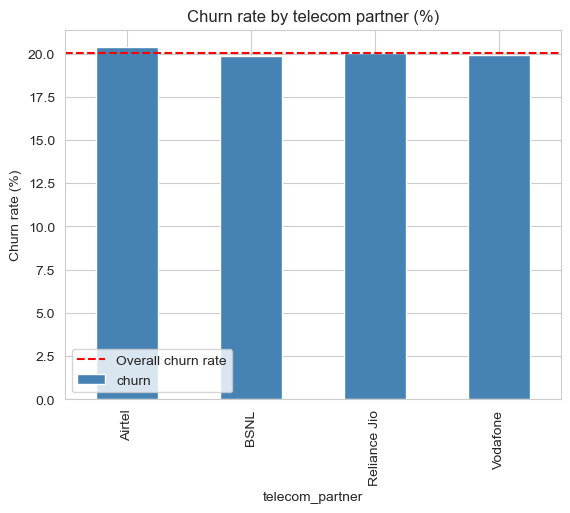

In [13]:
partner_churn = df_clean.groupby("telecom_partner")["churn"].mean() * 100
partner_churn.plot(kind="bar", color="steelblue")
plt.axhline(df_clean["churn"].mean() * 100, color="red", linestyle="--", label="Overall churn rate")
plt.title("Churn rate by telecom partner (%)")
plt.ylabel("Churn rate (%)")
plt.legend()
plt.show()

**Observation:** churn rates are very close to the overall rate of about 20% across telecom partners (Airtel 20.37%, BSNL 19.86%, Reliance Jio 20.02%, Vodafone 19.95%), and the other groups and average values show the same pattern: customers who churn look almost identical to customers who stay.

**Inference:** no single customer group stands out as a clear churn group.

---
#  Preparing the Data for Modeling
##  Convert text columns to numbers
Models need numbers, so `telecom_partner`, `gender`, `state` and `city` are converted to 0/1 columns (one-hot encoding).

In [14]:
df_model = pd.get_dummies(df_clean, columns=["telecom_partner", "gender", "state", "city"], drop_first=True, dtype=int)
print("Shape:", df_model.shape)

Shape: (243553, 44)


## Correlation with churn

In [15]:
corr_with_churn = df_model.corr()["churn"].drop("churn").abs().sort_values(ascending=False)
print(corr_with_churn.head(10).round(4))

state_Jharkhand      0.0052
gender_M             0.0051
city_Hyderabad       0.0041
estimated_salary     0.0033
city_Delhi           0.0033
city_Chennai         0.0033
state_Karnataka      0.0032
state_West Bengal    0.0031
sms_sent             0.0031
state_Punjab         0.0030
Name: churn, dtype: float64


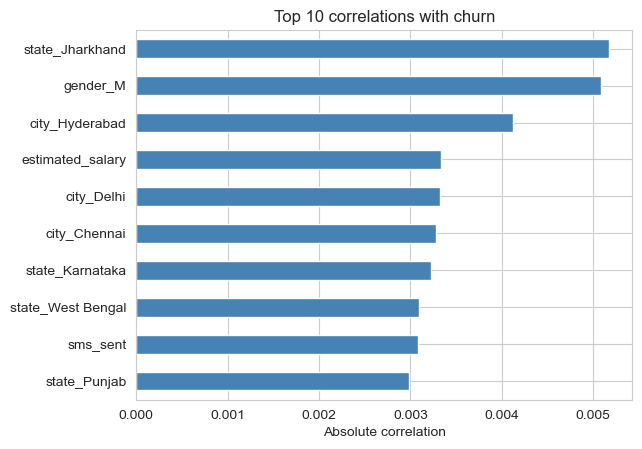

In [16]:
corr_with_churn.head(10).sort_values().plot(kind="barh", color="steelblue")
plt.title("Top 10 correlations with churn")
plt.xlabel("Absolute correlation")
plt.show()

**Observation:** the strongest correlation between any column and churn is only **0.0052**, and the next ones are about 0.003. A correlation this close to 0 means essentially no relationship.

**Inference:** the data has very little information for predicting churn. I expect all models to perform close to random guessing (ROC-AUC about 0.50).

## Train/test split and scaling
The data is split 80% train and 20% test. `stratify=y` keeps the same churn share (about 20%) in both parts. The scaler (needed for Logistic Regression) learns from the training data only, to avoid data leakage.

In [17]:
X = df_model.drop("churn", axis=1)    # inputs
y = df_model["churn"]                 # answer

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

print("Train:", X_train.shape, " Test:", X_test.shape)
print("Churn share in train:", round(y_train.mean(), 4), " in test:", round(y_test.mean(), 4))

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)   # learn from train only
X_test_s = scaler.transform(X_test)

Train: (194842, 43)  Test: (48711, 43)
Churn share in train: 0.2005  in test: 0.2005


---
# Model Building and Comparison
Eight models are trained: a **Dummy baseline** (learns nothing, so it shows what "random guessing" scores), Logistic Regression, Naive Bayes, Decision Tree, Random Forest, Hist Gradient Boosting, LightGBM and XGBoost. Models that support it use class weights to handle the imbalance.

In [18]:
ratio = (y_train == 0).sum() / (y_train == 1).sum()   # about 4 (stay : churn)

# name: (model, does it need scaled data?)
models = {
    "Dummy (baseline)": (DummyClassifier(strategy="prior"),False),
    "Logistic Regression": (LogisticRegression(class_weight="balanced",max_iter=1000),True),
    "Naive Bayes": (GaussianNB(),False),
    "Decision Tree": (DecisionTreeClassifier(max_depth=5,class_weight="balanced",random_state=42),False),
    "Random Forest": (RandomForestClassifier(n_estimators=100, max_depth=10,class_weight="balanced",n_jobs=-1,random_state=42),False),
    "Hist Gradient Boosting": (HistGradientBoostingClassifier(max_iter=200,learning_rate=0.05,random_state=42),False),
    "LightGBM": (LGBMClassifier(n_estimators=300,learning_rate=0.05,is_unbalance=True,random_state=42,verbose=-1),False),
    "XGBoost": (XGBClassifier(n_estimators=200,learning_rate=0.05,max_depth=4,scale_pos_weight=ratio,eval_metric="auc",n_jobs=-1,random_state=42),False),
}

probas = {}    # saves each model's churn probabilities on the test data
for name, (model, scaled) in models.items():
    if scaled:
        model.fit(X_train_s, y_train)
        probas[name] = model.predict_proba(X_test_s)[:, 1]
    else:
        model.fit(X_train, y_train)
        probas[name] = model.predict_proba(X_test)[:, 1]
    print(name, "trained")

Dummy (baseline) trained
Logistic Regression trained
Naive Bayes trained
Decision Tree trained
Random Forest trained
Hist Gradient Boosting trained
LightGBM trained
XGBoost trained


In [19]:
rows = []
for name, proba in probas.items():
    pred = (proba >= 0.5).astype(int)      # 1 if the probability is 0.5 or more
    rows.append({"Model": name,
                 "ROC-AUC": roc_auc_score(y_test, proba),
                 "Precision": precision_score(y_test, pred, zero_division=0),
                 "Recall": recall_score(y_test, pred),
                 "F1": f1_score(y_test, pred, zero_division=0)})

results = pd.DataFrame(rows).sort_values("ROC-AUC", ascending=False).reset_index(drop=True).round(4)
results

,Model,ROC-AUC,Precision,Recall,F1
0,Logistic Regression,0.5059,0.2019,0.4988,0.2875
1,Random Forest,0.5041,0.2017,0.3337,0.2514
2,Naive Bayes,0.5004,0.0000,0.0000,0.0000
3,Dummy (baseline),0.5000,0.0000,0.0000,0.0000
4,Hist Gradient Boosting,0.4997,0.0000,0.0000,0.0000
5,LightGBM,0.4997,0.1971,0.4584,0.2756
6,Decision Tree,0.4995,0.1997,0.8531,0.3236
7,XGBoost,0.4982,0.1999,0.5007,0.2857


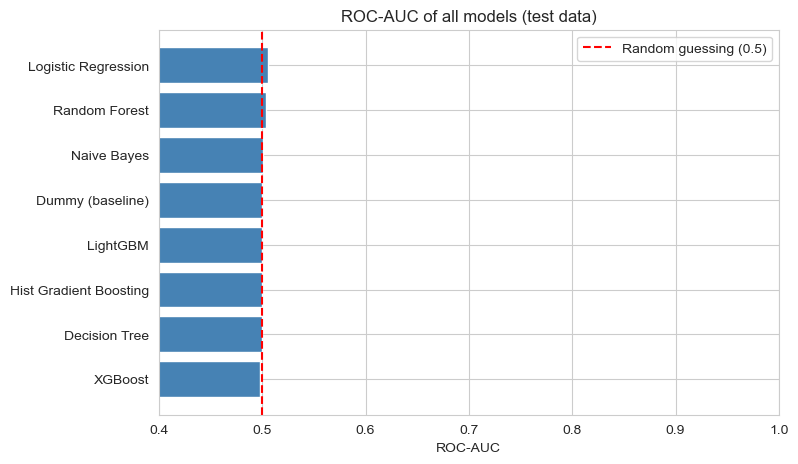

In [20]:
plot_data = results.sort_values("ROC-AUC")
plt.figure(figsize=(8, 5))
plt.barh(plot_data["Model"], plot_data["ROC-AUC"], color="steelblue")
plt.axvline(0.5, color="red", linestyle="--", label="Random guessing (0.5)")
plt.xlim(0.4, 1.0)
plt.title("ROC-AUC of all models (test data)")
plt.xlabel("ROC-AUC")
plt.legend()
plt.show()

**Observation:** every model, including the Dummy baseline, has a test ROC-AUC of about **0.50**. Models are compared by ROC-AUC because precision, recall and F1 depend on the 0.5 cut-off. Some models (for example Naive Bayes and Hist Gradient Boosting) show precision, recall and F1 of 0 because they predict almost nobody as a churner at that cut-off, which does not mean they are better or worse.

**Inference:** no model is clearly better than another, and none is better than random guessing.

---
#  Cross-Validation
Cross-validation trains and tests a model 5 times on different parts of the training data. It is more reliable than a single split, because one lucky split cannot fool us. For speed it uses a 50,000-row sample of the training data. `make_pipeline` scales the data inside each fold, so there is no data leakage.

In [21]:
X_cv = X_train.sample(n=min(50000, len(X_train)), random_state=42)
y_cv = y_train.loc[X_cv.index]

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_models = {
    "Logistic Regression": make_pipeline(StandardScaler(),LogisticRegression(class_weight="balanced",max_iter=1000)),
    "Decision Tree": DecisionTreeClassifier(max_depth=5,class_weight="balanced",random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100,max_depth=10,class_weight="balanced",n_jobs=-1,random_state=42),
    "LightGBM": LGBMClassifier(n_estimators=300,learning_rate=0.05,is_unbalance=True,random_state=42,verbose=-1),
    "XGBoost": XGBClassifier(n_estimators=200,learning_rate=0.05,max_depth=4,scale_pos_weight=ratio,eval_metric="auc",n_jobs=-1,random_state=42),
}

cv_rows = []
for name, model in cv_models.items():
    scores = cross_val_score(model, X_cv, y_cv, cv=skf, scoring="roc_auc")
    cv_rows.append({"Model": name, "Mean ROC-AUC": scores.mean(), "Std": scores.std(), "Min": scores.min(), "Max": scores.max()})
    print(name, "->", scores.round(4))

cv_results = pd.DataFrame(cv_rows).sort_values("Mean ROC-AUC", ascending=False).reset_index(drop=True).round(4)
cv_results

Logistic Regression -> [0.4968 0.4897 0.4874 0.4937 0.4867]
Decision Tree -> [0.4953 0.4924 0.5031 0.5023 0.4954]
Random Forest -> [0.5003 0.5111 0.5068 0.4993 0.4847]
LightGBM -> [0.5075 0.5052 0.5128 0.5128 0.4924]
XGBoost -> [0.5048 0.512  0.5061 0.5031 0.4909]


,Model,Mean ROC-AUC,Std,Min,Max
0,LightGBM,0.5061,0.0075,0.4924,0.5128
1,XGBoost,0.5034,0.0069,0.4909,0.5120
2,Random Forest,0.5004,0.0090,0.4847,0.5111
3,Decision Tree,0.4977,0.0042,0.4924,0.5031
4,Logistic Regression,0.4909,0.0039,0.4867,0.4968


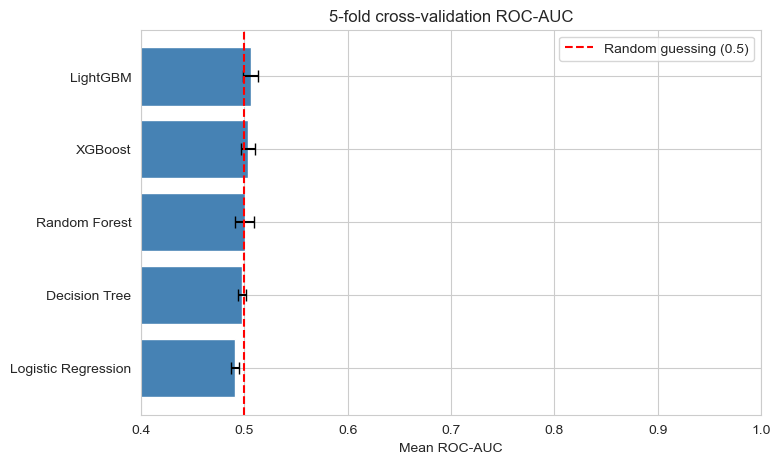

In [22]:
plot_data = cv_results.sort_values("Mean ROC-AUC")
plt.figure(figsize=(8, 5))
plt.barh(plot_data["Model"], plot_data["Mean ROC-AUC"], xerr=plot_data["Std"], color="steelblue", capsize=4)
plt.axvline(0.5, color="red", linestyle="--", label="Random guessing (0.5)")
plt.xlim(0.4, 1.0)
plt.title("5-fold cross-validation ROC-AUC")
plt.xlabel("Mean ROC-AUC")
plt.legend()
plt.show()

**Observation (5-fold stratified cross-validation):** all models have a mean ROC-AUC of about 0.49 to 0.51 (LightGBM 0.5061, XGBoost 0.5034, Random Forest 0.5004, Decision Tree 0.4977, Logistic Regression 0.4909) with small standard deviations (0.004 to 0.009). The differences are within noise, so no model is better than another.

---
# Hyperparameter Tuning
Hyperparameters are settings chosen before training (for example the number of trees). Tuning tries many combinations and keeps the best one, judged by cross-validated ROC-AUC. **GridSearchCV** tries every combination, and **RandomizedSearchCV** tries a random selection.

In [23]:
# Logistic Regression: GridSearch (C controls the strength of regularization)
lr_pipe = make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=1000))
lr_params = {"logisticregression__C": [0.001, 0.01, 0.1, 1, 10]}

lr_grid = GridSearchCV(lr_pipe, lr_params, cv=3, scoring="roc_auc", n_jobs=-1)
lr_grid.fit(X_cv, y_cv)

print("Best settings:", lr_grid.best_params_)
print("Best CV ROC-AUC:", round(lr_grid.best_score_, 4))

Best settings: {'logisticregression__C': 0.001}
Best CV ROC-AUC: 0.4921


In [24]:
# LightGBM: RandomizedSearch (15 random combinations)
lgbm_params = {
    "num_leaves": [8, 15, 31, 63],
    "learning_rate": [0.01, 0.03, 0.05, 0.1],
    "n_estimators": [100, 200, 300, 500],
    "min_child_samples": [20, 50, 100, 200],
    "colsample_bytree": [0.5, 0.7, 1.0],
    "subsample": [0.7, 0.85, 1.0],
    "reg_lambda": [0, 1, 5, 10],
}

lgbm_search = RandomizedSearchCV(
    LGBMClassifier(is_unbalance=True, subsample_freq=1, random_state=42, verbose=-1),
    param_distributions=lgbm_params, n_iter=15, cv=3, scoring="roc_auc",
    random_state=42, n_jobs=1, verbose=1)
lgbm_search.fit(X_cv, y_cv)

print("Best settings:", lgbm_search.best_params_)
print("Best CV ROC-AUC:", round(lgbm_search.best_score_, 4))

Fitting 3 folds for each of 15 candidates, totalling 45 fits
Best settings: {'subsample': 0.85, 'reg_lambda': 0, 'num_leaves': 63, 'n_estimators': 100, 'min_child_samples': 20, 'learning_rate': 0.03, 'colsample_bytree': 1.0}
Best CV ROC-AUC: 0.5074


In [25]:
# Random Forest: RandomizedSearch
rf_params = {
    "n_estimators": [100, 200],
    "max_depth": [5, 10, 15],
    "min_samples_leaf": [10, 50, 100],
}

rf_search = RandomizedSearchCV(
    RandomForestClassifier(class_weight="balanced", n_jobs=-1, random_state=42),
    param_distributions=rf_params, n_iter=6, cv=3, scoring="roc_auc", random_state=42, n_jobs=1, verbose=1)
rf_search.fit(X_cv, y_cv)

print("Best settings:", rf_search.best_params_)
print("Best CV ROC-AUC:", round(rf_search.best_score_, 4))

Fitting 3 folds for each of 6 candidates, totalling 18 fits
Best settings: {'n_estimators': 200, 'min_samples_leaf': 10, 'max_depth': 15}
Best CV ROC-AUC: 0.5017


In [26]:
before_after = pd.DataFrame({
    "Model": ["Logistic Regression", "LightGBM", "Random Forest"],
    "CV ROC-AUC before tuning": [
        cv_results.loc[cv_results["Model"] == "Logistic Regression", "Mean ROC-AUC"].values[0],
        cv_results.loc[cv_results["Model"] == "LightGBM", "Mean ROC-AUC"].values[0],
        cv_results.loc[cv_results["Model"] == "Random Forest", "Mean ROC-AUC"].values[0]],
    "CV ROC-AUC after tuning": [round(lr_grid.best_score_, 4), round(lgbm_search.best_score_, 4), round(rf_search.best_score_, 4)]
})
before_after

,Model,CV ROC-AUC before tuning,CV ROC-AUC after tuning
0,Logistic Regression,0.4909,0.4921
1,LightGBM,0.5061,0.5074
2,Random Forest,0.5004,0.5017


**Observation:** Logistic Regression (GridSearchCV) and LightGBM and Random Forest (RandomizedSearchCV, 3-fold CV, scoring ROC-AUC) were tuned. The best CV ROC-AUC improved only from 0.4909 to 0.4921 (Logistic Regression) and from 0.5061 to 0.5074 (LightGBM). Gains of about 0.001 are noise: the best score out of many tries always looks slightly higher by luck.

---
# Final Model Evaluation (Unseen Test Data)
The tuned LightGBM is trained on the full training data and tested on customers it has never seen.

In [27]:
final_model = LGBMClassifier(**lgbm_search.best_params_, is_unbalance=True, subsample_freq=1, random_state=42, verbose=-1)
final_model.fit(X_train, y_train)

final_proba = final_model.predict_proba(X_test)[:, 1]
final_pred = (final_proba >= 0.5).astype(int)

print("Test ROC-AUC (tuned LightGBM)   :", round(roc_auc_score(y_test, final_proba), 6))
print("Test ROC-AUC (untuned LightGBM) :", round(roc_auc_score(y_test, probas["LightGBM"]), 6))
print("Precision:", round(precision_score(y_test, final_pred, zero_division=0), 4))
print("Recall   :", round(recall_score(y_test, final_pred), 4))
print("F1       :", round(f1_score(y_test, final_pred, zero_division=0), 4))

Test ROC-AUC (tuned LightGBM)   : 0.499705
Test ROC-AUC (untuned LightGBM) : 0.499653
Precision: 0.2011
Recall   : 0.0678
F1       : 0.1014


              precision    recall  f1-score   support

    Stay (0)       0.80      0.93      0.86     38946
   Churn (1)       0.20      0.07      0.10      9765

    accuracy                           0.76     48711
   macro avg       0.50      0.50      0.48     48711
weighted avg       0.68      0.76      0.71     48711



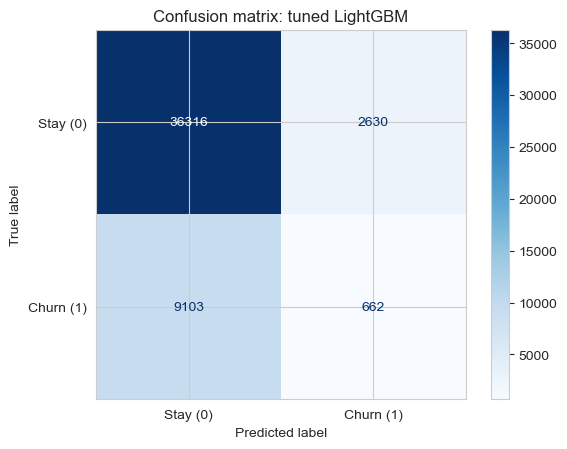

In [28]:
print(classification_report(y_test, final_pred, target_names=["Stay (0)", "Churn (1)"], zero_division=0))

ConfusionMatrixDisplay(confusion_matrix(y_test, final_pred), display_labels=["Stay (0)", "Churn (1)"]).plot(cmap="Blues", values_format="d")
plt.title("Confusion matrix: tuned LightGBM")
plt.show()

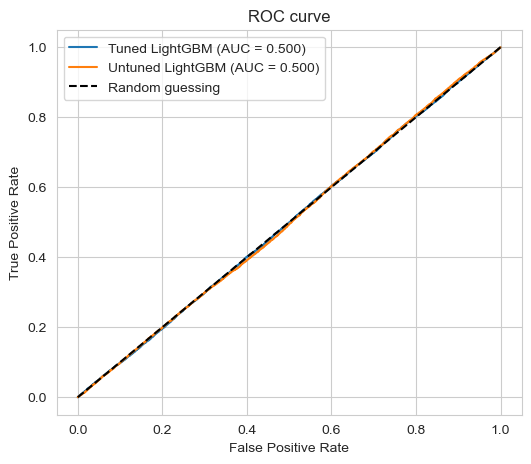

In [29]:
fpr, tpr, _ = roc_curve(y_test, final_proba)
fpr2, tpr2, _ = roc_curve(y_test, probas["LightGBM"])

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"Tuned LightGBM (AUC = {roc_auc_score(y_test, final_proba):.3f})")
plt.plot(fpr2, tpr2, label=f"Untuned LightGBM (AUC = {roc_auc_score(y_test, probas['LightGBM']):.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random guessing")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC curve")
plt.legend()
plt.show()

## Is the score really different from 0.5? (confidence interval)
The test data is re-sampled 200 times to see how much the ROC-AUC varies by chance.

In [30]:
rng = np.random.RandomState(42)
y_arr = y_test.values
aucs = []
for _ in range(200):
    idx = rng.choice(len(y_arr), len(y_arr), replace=True)
    aucs.append(roc_auc_score(y_arr[idx], final_proba[idx]))

low, high = np.percentile(aucs, [2.5, 97.5])
print(f"95% confidence interval for ROC-AUC: {low:.4f} to {high:.4f}")
print("Does the interval include 0.5?", low <= 0.5 <= high)

95% confidence interval for ROC-AUC: 0.4939 to 0.5066
Does the interval include 0.5? True


## Real churn rate by predicted risk group
Test customers are split into 10 groups by predicted risk (1 = lowest, 10 = highest). A useful model shows low churn in group 1 and much higher churn in group 10.

risk_group
1     19.93
2     19.81
3     20.71
4     19.32
5     20.59
6     19.71
7     20.55
8     20.43
9     19.75
10    19.67
Name: churn, dtype: float64


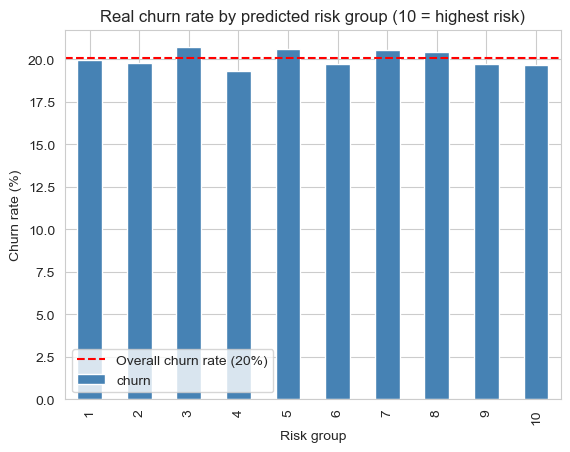

In [31]:
test_check = pd.DataFrame({"churn": y_test.values, "score": final_proba})
test_check["risk_group"] = pd.qcut(test_check["score"], 10, labels=False, duplicates="drop") + 1

decile_table = (test_check.groupby("risk_group")["churn"].mean() * 100).round(2)
print(decile_table)

decile_table.plot(kind="bar", color="steelblue")
plt.axhline(y_test.mean() * 100, color="red", linestyle="--", label="Overall churn rate (20%)")
plt.title("Real churn rate by predicted risk group (10 = highest risk)")
plt.xlabel("Risk group")
plt.ylabel("Churn rate (%)")
plt.legend()
plt.show()

## Choosing a threshold

In [32]:
p, r, t = precision_recall_curve(y_test, final_proba)
f1_values = 2 * p * r / (p + r + 1e-12)
best = f1_values[:-1].argmax()

print("Threshold with best F1:", round(t[best], 3))
print("Precision:", round(p[best], 4), " Recall:", round(r[best], 4), " F1:", round(f1_values[best], 4))

Threshold with best F1: 0.287
Precision: 0.2005  Recall: 1.0  F1: 0.334


In [33]:
summary = pd.DataFrame({
    "Model": ["Dummy baseline (learns nothing)", "LightGBM (before tuning)", "LightGBM (after tuning)"],
    "Test ROC-AUC": [round(roc_auc_score(y_test, probas["Dummy (baseline)"]), 4),
                     round(roc_auc_score(y_test, probas["LightGBM"]), 4),
                     round(roc_auc_score(y_test, final_proba), 4)]
})
summary

,Model,Test ROC-AUC
0,Dummy baseline (learns nothing),0.5000
1,LightGBM (before tuning),0.4997
2,LightGBM (after tuning),0.4997


**Observation:**
- The tuned LightGBM has a test ROC-AUC of about 0.50 (95% confidence interval 0.4939 to 0.5066, which **includes 0.5**), the same as the Dummy baseline.
- The ROC curve follows the diagonal, and the real churn rate is flat at about 20% in all 10 predicted-risk groups.
- The best-F1 threshold (0.287) gives recall of 1.0 and precision of about 0.2005, which means it flags **everybody** and is not useful.

**Inference:** tuning and cross-validation confirm that the model cannot predict churn better than random guessing.

---
#  Sanity Test of the Pipeline
To check that the 0.50 result is caused by the data and not by a coding mistake, I add an artificial column that really is related to churn (plus random noise) and train the same type of model. If the pipeline works, the ROC-AUC should rise clearly above 0.50. (These fake columns are used only for this test.)

In [34]:
rng = np.random.RandomState(0)
X_train_fake = X_train.copy()
X_test_fake = X_test.copy()
X_train_fake["fake_signal"] = y_train.values + rng.normal(0, 1, len(y_train))
X_test_fake["fake_signal"] = y_test.values + rng.normal(0, 1, len(y_test))

check_model = LGBMClassifier(n_estimators=100, random_state=42, verbose=-1)
check_model.fit(X_train_fake, y_train)

print("ROC-AUC with an artificial signal:",round(roc_auc_score(y_test, check_model.predict_proba(X_test_fake)[:, 1]), 4))

ROC-AUC with an artificial signal: 0.7624


**Observation:** with an artificial signal the ROC-AUC rises to about **0.76**.

**Inference:** the code and pipeline work and can find a pattern when one exists. The 0.50 result is therefore caused by the **data**: the available columns carry almost no information about churn.

---
# Variables Influencing Churn
Random Forest feature importance shows which columns the model used most.

estimated_salary                0.1434
data_used                       0.1368
tenure_days                     0.1290
calls_made                      0.1159
age                             0.1023
sms_sent                        0.1008
num_dependents                  0.0444
gender_M                        0.0166
telecom_partner_Reliance Jio    0.0141
telecom_partner_BSNL            0.0135
dtype: float64


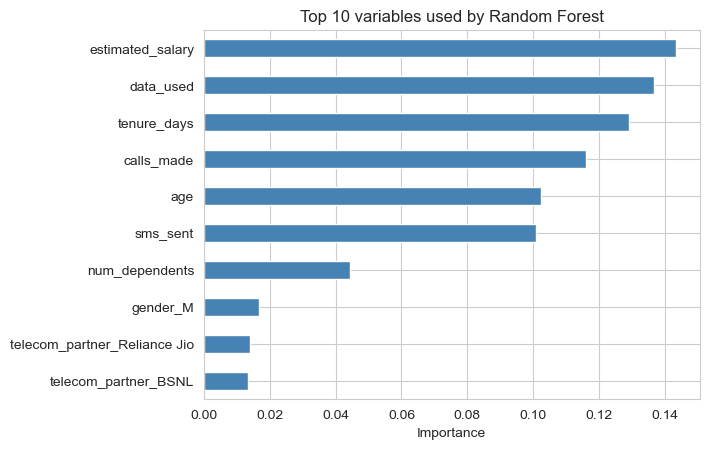

In [35]:
rf = models["Random Forest"][0]
importance = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
print(importance.head(10).round(4))

importance.head(10).sort_values().plot(kind="barh", color="steelblue")
plt.title("Top 10 variables used by Random Forest")
plt.xlabel("Importance")
plt.show()

**Observation:** the importances are small and similar, and columns with many different values (such as `estimated_salary`, `data_used` and `tenure_days`) rank highest simply because they offer more places to split the data.

**Inference:** **no variable shows a real influence on churn in this dataset.** The strongest correlation with churn is only 0.0052, and churn rates are almost identical across telecom partners (19.86% to 20.37%). The importance chart only shows which columns the model used most, not which columns cause churn.

---
### Churn Risk Score and CHURN-FLAG
## Performance check on unseen test customers
The risk score (0 to 100) is the model's churn probability times 100. Customers are split into Low, Medium and High risk. `CHURN-FLAG` is YES for the 20% of customers with the highest score (about 20% of customers really churn).

To judge honestly whether the score works, it is checked **only on test customers** (data the model has never seen).

In [36]:
lgbm = models["LightGBM"][0]

test_scores = pd.DataFrame({
    "churn": y_test.values, "Churn_Risk_Score": (lgbm.predict_proba(X_test)[:, 1] * 100).round(1)
})
test_scores["Risk_Level"] = pd.qcut(test_scores["Churn_Risk_Score"], 3, labels=["Low", "Medium", "High"])
print("Churn rate by risk level (%), test data only:")
print((test_scores.groupby("Risk_Level")["churn"].mean() * 100).round(2))

cutoff = test_scores["Churn_Risk_Score"].quantile(0.80)
test_scores["CHURN-FLAG"] = (test_scores["Churn_Risk_Score"] >= cutoff).astype(int)
test_scores["CHURN-FLAG-LABEL"] = test_scores["CHURN-FLAG"].map({1: "YES", 0: "NO"})
print("\nChurn rate of YES vs NO customers (%), test data only:")
print((test_scores.groupby("CHURN-FLAG-LABEL")["churn"].mean() * 100).round(2))

Churn rate by risk level (%), test data only:
Risk_Level
Low       19.92
Medium    20.26
High      19.95
Name: churn, dtype: float64

Churn rate of YES vs NO customers (%), test data only:
CHURN-FLAG-LABEL
NO     20.07
YES    19.96
Name: churn, dtype: float64


**Observation:** on unseen test data the churn rate is about 19.9% (Low), 20.3% (Medium) and 20.0% (High) risk, and about 20.0% for customers flagged YES versus 20.1% for NO.

**Inference:** the churn risk score and `CHURN-FLAG` have been created as the brief asks, but **they cannot separate churners from non-churners** on this data. (Scoring the customers the model was trained on looks better only because the model memorized them, so it is not used to judge performance.) They should not be used for real campaigns until the model is rebuilt with more informative data.

##  Scores, flag and campaign list for all customers
This is the deliverable the brief asks for: every customer receives a risk score, a risk level and a `CHURN-FLAG`, and the YES customers form the email campaign list. It shows the process only; the table above shows that on this data it does not find churners better than chance.

In [37]:
df_final = df_clean.copy()
df_final["Churn_Risk_Score"] = (lgbm.predict_proba(X)[:, 1] * 100).round(1)       # 0 to 100
df_final["Risk_Level"] = pd.qcut(df_final["Churn_Risk_Score"], 3, labels=["Low", "Medium", "High"])

cutoff_all = df_final["Churn_Risk_Score"].quantile(0.80)
df_final["CHURN-FLAG"] = (df_final["Churn_Risk_Score"] >= cutoff_all).astype(int)
df_final["CHURN-FLAG-LABEL"] = df_final["CHURN-FLAG"].map({1: "YES", 0: "NO"})

print(df_final["CHURN-FLAG-LABEL"].value_counts())

campaign_list = df_final[df_final["CHURN-FLAG"] == 1]
print("\nCustomers to target with the email campaign:", len(campaign_list))

df_final.to_csv("churn_scores_and_flags.csv", index=False)
campaign_list.head()

CHURN-FLAG-LABEL
NO     192615
YES     50938
Name: count, dtype: int64

Customers to target with the email campaign: 50938


,telecom_partner,gender,age,state,city,num_dependents,estimated_salary,calls_made,sms_sent,data_used,churn,tenure_days,Churn_Risk_Score,Risk_Level,CHURN-FLAG,CHURN-FLAG-LABEL
2,Vodafone,F,57,Arunachal Pradesh,Delhi,0,148828,49,24,193,1,1219,56.3,High,1,YES
3,BSNL,M,46,Tamil Nadu,Kolkata,1,38722,80,25,9377,1,1219,55.1,High,1,YES
7,BSNL,M,46,Arunachal Pradesh,Kolkata,4,104541,87,40,2245,1,1219,53.5,High,1,YES
11,Airtel,M,56,Odisha,Mumbai,4,135129,39,51,7644,0,1219,54.5,High,1,YES
12,Vodafone,F,64,Uttar Pradesh,Hyderabad,4,136967,40,4,1911,0,1219,53.1,High,1,YES


---
#  Business Use Cases: Customer Care and Ticket Priority
The risk level can drive simple actions for each team.

In [38]:
df_final["Ticket_Priority"] = df_final["Risk_Level"].map(
    {"High": "High priority", "Medium": "Normal priority", "Low": "Standard"})

df_final["Recommended_Action"] = df_final["Risk_Level"].map(
    {"High": "Email retention offer + proactive call from customer care",
     "Medium": "Email offer",
     "Low": "No action"})

df_final[["CHURN-FLAG-LABEL", "Risk_Level", "Ticket_Priority", "Recommended_Action"]].head(10)

,CHURN-FLAG-LABEL,Risk_Level,Ticket_Priority,Recommended_Action
0,NO,High,High priority,Email retention offer + proactive call from cu...
1,NO,Low,Standard,No action
2,YES,High,High priority,Email retention offer + proactive call from cu...
3,YES,High,High priority,Email retention offer + proactive call from cu...
4,NO,Low,Standard,No action
5,NO,Low,Standard,No action
6,NO,Low,Standard,No action
7,YES,High,High priority,Email retention offer + proactive call from cu...
8,NO,Low,Standard,No action
9,NO,Low,Standard,No action


## How No-Churn can use this

| Use case | How the model output is used |
|---|---|
| **Retention email campaigns** | Customers with CHURN-FLAG = YES receive emails with offers (the campaign list above) |
| **Customer care attention** | High-risk customers get a proactive call or priority handling at touch points |
| **Request fulfilment** | Requests from High-risk customers are completed first |
| **Ticket prioritisation** | Tickets from High-risk customers are automatically marked High priority for quick resolution (`Ticket_Priority`) |
| **Monitoring** | Churn rates by risk level are tracked monthly and the model is retrained with new data |

**Important limitation:** on this dataset the risk score cannot separate churners from non-churners (about 20% churn in every risk level on unseen test data). These actions should therefore **not be applied to real customers yet**. Before going live, the company should:
1. Rebuild the model with more informative data (customer-service calls, complaints, billing and plan details, network quality).
2. Run a small **pilot**: send the offer to flagged customers and keep a similar group as a control group, then compare churn between the two groups.
3. Use the model only if the High-risk group churns clearly more than the Low-risk group.

---
# 14. Conclusion

## Summary
The goal was to help No-Churn Telecom understand why customers leave, score each customer's churn risk, and create a `CHURN-FLAG` (YES/NO) for retention campaigns. The data was loaded from the MySQL table `telecom_churn_data` (243,553 customers, 14 columns). About 20% of customers churn (48,827 churned vs 194,726 stayed), so the data is imbalanced and accuracy is not a reliable metric.

## What I did
- **Data preparation:** no missing values or duplicates. Negative values in `calls_made` (6,713), `sms_sent` (7,375) and `data_used` (6,050) were replaced with 0. `customer_id` and `pincode` were dropped as identifiers, and the registration date was converted to `tenure_days`.
- **Analysis (Goal 1):** churn rates were almost identical across telecom partners (19.86% to 20.37%) and other groups. The strongest correlation between any variable and churn was only 0.0052.
- **Modeling:** 8 models were compared (Dummy baseline, Logistic Regression, Naive Bayes, Decision Tree, Random Forest, Hist Gradient Boosting, LightGBM, XGBoost). I then ran 5-fold cross-validation and hyperparameter tuning (GridSearchCV and RandomizedSearchCV), and finally evaluated on unseen test data.

## Results
| Check | Result |
|---|---|
| Test ROC-AUC of all models | about 0.50, the same as the Dummy baseline |
| 5-fold cross-validation (mean ROC-AUC) | LightGBM 0.5061, XGBoost 0.5034, Random Forest 0.5004, Decision Tree 0.4977, Logistic Regression 0.4909 |
| Effect of tuning | LightGBM 0.5061 to 0.5074, Logistic Regression 0.4909 to 0.4921 (noise, about 0.001) |
| Tuned LightGBM on the test set | ROC-AUC about 0.50, 95% confidence interval 0.4939 to 0.5066, which includes 0.5 |
| Real churn rate by predicted risk level (test data) | Low 19.92%, Medium 20.26%, High 19.95% |
| CHURN-FLAG on test data | YES 19.96% vs NO 20.07% |
| Best-F1 threshold (0.287) | recall 1.0, precision about 0.2005: it flags everyone and is not useful |
| Sanity test with an artificial signal | ROC-AUC rose to about 0.76 |

## Project goals
1. **Variables influencing churn:** no variable was found that clearly influences churn. The feature importances are small and similar, and do not show a real driver.
2. **Churn risk scores:** scores (0 to 100) and risk levels were created for every customer. On unseen test data they do not separate churners from non-churners, since churn is about 20% in every level.
3. **CHURN-FLAG:** the YES/NO flag and a campaign list (about 50,900 customers flagged YES) were created as the brief asks. On the test data, flagged customers churn at the same rate as the rest, so the flag is not yet useful for real campaigns.

## Why the models could not predict churn
The result does not depend on the algorithm. All models, cross-validation, tuning and a confidence interval agree at about 0.50. The sanity test, which added an artificial signal and raised the ROC-AUC to about 0.76, shows that the code and pipeline work. The limitation is therefore the data: the available columns carry almost no information about churn. (Scores computed on the training customers looked better only because the models had memorized them, so all performance claims use unseen test data.)

## Recommendations
- **Do not use the current score or flag for real campaigns.** Contacting the flagged customers would be no better than contacting customers at random.
- **Collect more relevant data:** customer-service calls, complaints, billing and payment issues, plan and contract details, service quality and network problems, and customer support interactions.
- **Validate the churn definition** and the data source, including the negative usage values.
- **Check the dataset with the project mentor.** The project brief describes a table with 4,617 rows and 21 columns (for example Day Mins, CustServ Calls, International Plan), but the database table has 243,553 rows and 14 columns. The brief's table would be expected to contain stronger churn signals.
- **Once better data is available,** rebuild the model with the same pipeline, evaluate it on unseen data (ROC-AUC, precision, recall, F1), run a pilot with a control group, and use the risk scores to prioritize email offers, customer-care attention and high-priority ticket handling.

## Final note
This project shows that a careful process (data checks, an imbalance-aware setup, a baseline, cross-validation, tuning, a confidence interval and a sanity test) can show whether a model is truly useful. Here it shows the available data is not good enough to predict churn, and it points to what data is needed next.